# UNSW kinetic-inductance parametric amplifier (KIPA, device BA13), topology rebuilt in the Quantcore PDK

**What it is.** A KIPA: a λ/4 CPW resonator of a high-kinetic-inductance film, shorted at one end and bounded at
the other by a stepped-impedance filter (SIF) — alternating low- and high-impedance λ/4 sections that act as a
Bragg mirror for the resonance while letting a DC bias through. DC + pump give three-wave mixing in the resonator.
In this device the shorted end is a 1 µm wire carrying the largest current density, under which bismuth donor
spins sit: the amplifier amplifies their echoes in situ (Vine et al., arXiv:2211.11333; the KIPA of Parker et al.,
PR Applied 17, 034064 (2022)).

**Source.** Zenodo 7600250 (CC BY 4.0), `BA13_device_gds.GDS` (one cell `DEVICE`; 0/0 die 4 × 11 mm, 7/0 and 8/0
wide / narrow centre conductors, 9/0 the 1 µm wire, 10/0 ground), downloaded into its own folder
`build/external/kipa_zenodo_7600250/` and only read. Measured from the GDS:

| section | centre / gap (µm) | length (µm) |
|---|---|---|
| feed | 100 / 45 | ≈ 1700 (with its taper) |
| SIF low-Z × 4 | 138 / 6 | ≈ 3400 |
| SIF high-Z × 3 | 10 / 70 | ≈ 3455 |
| resonator | 5 / 15 | ≈ 2981 |
| wire (spin region) | 1 / 10 | ≈ 1750, shorted to ground |

**This is a topology rebuild in the Quantcore PDK**: the same section sequence drawn with our routes (each section
a qcc route of its own width, joined by `CpweTaper`s), a `BondPad` on the south edge, the short as a route free end
(`term=0`), on our Nb film. The source film (NbTiN, strongly kinetic) is not stated in the GDS; the analysis runs on
the PDK Nb film. The rows are re-folded with 300 µm U-turns (the source's own serpentine is close to it).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the 4 × 11 mm die, the south bond pad, the 100/45 µm feed with the first
taper, the section boundaries of the stepped-impedance filter and of the resonator (on a kinetic film the λ/4
resonator is the nonlinear element), the SIF sections, the resonator and the shorted spin wire as routes, and then the
whole chip (the sim group, the save). Then the same steps as the Flow strip of the Quantcore KLayout plugin: **Check**
(DRC, netlist) → **LOM** (the amplifier's circuit models, their plots, one change by hand) → **Simulate** (export to
HFSS and the resonator's Q3D C-matrix; no eigenmode or full-wave run, said why) → **Results** (the Q3D capacitances
read against the CPW formula, a feedback step and the iteration to a resonance inside the SIF stop band) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in four cells, with its outputs) is kept as `unsw_kipa.v1.ipynb`; both save the same
`unsw_kipa.json`.

## Setup

The imports, the output folder and the switches. `SECTIONS`, `RES` and `WIRE` are the source's section table (widths
and lengths measured from its GDS, the title's table). `_amplifiers` holds the amplifier notebooks' helpers (the PDK
facts, value tables, plots, the linear S-parameters of a LOM netlist, and the readers that put kept FEM results in
amplifier terms); `_common` the helpers all design notebooks share (tables, snapshots, the PDK placement, the FEM and
feedback steps). The physics is `quantcore_circuits.analysis.amplifiers`, the cells
`quantcore_circuits.layouts.others.amplifiers`.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
import os, sys
from pathlib import Path
import numpy as np
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "amplifiers"))
from _common import *
from _amplifiers import pdk_facts_md, plot, show_md, table_md
from _amplifiers import cmatrix_to_ground   # v2: kept FEM results in amplifier terms (Results)
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk
from quantcore_circuits.analysis import amplifiers as amp
from quantcore_circuits.analysis.synthesis import cpw_properties

LIVE = os.environ.get("QCC_LIVE", "1") == "1"
OUT = Path("examples/designs/amplifiers")
PDK = get_pdk()
SECTIONS = [("S0", 138, 6, 3400), ("S1", 10, 70, 3455), ("S2", 138, 6, 3400), ("S3", 10, 70, 3455),
            ("S4", 138, 6, 3400), ("S5", 10, 70, 3455), ("S6", 138, 6, 3394)]
RES, WIRE = (5, 15, 2981), (1, 10, 1750)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the film's kinetic inductance, the cheese and the 3/0
keep-outs. For this chip that means: the source's 4 × 11 mm die with the QCT frame (not the 7.5 mm standard), the bond
pad 100 µm from the south edge, and the PDK's Nb film: its small kinetic inductance (≈ 0.12 pH/□) is in every
section's Z0 and v_p, so on this film the resonator is mostly geometric (the source's film is not stated in its GDS).

In [4]:
show_md(pdk_facts_md(PDK))

| PDK | value |
|---|---|
| substrate | sapphire 650 µm, εr 10.25 |
| film | Nb 200 nm, λ_L 90 nm → L_s 0.116 pH/□ (kinetic, in every CPW / wire formula) |
| junction rule | Nb/AlOx/Nb trilayer, Δ 1.4 meV, J_c 0.163 µA/µm², R_n window 40–50 kΩ, fingers 0.1–2 µm |
| frame | die 7.5 × 7.5 mm standard, margin 100 µm, marker areas 500 µm, brand QCT |
| pad rule | outer etch 100 µm (one dicing-marker width) from the die edge (`edge="auto"`) |
| cheese | PDK band 3 rows of 5 µm squares, 20 µm gap, around the 3/0 keep-outs (unless the original has its own) |
| 3/0 keep-out | routes + 10 µm, components + 24 µm |

# Design: the layout, one segment at a time

An amplifier chip is laid out the way a designer would do it by hand: the die, the bond pads, the feed (and pump)
line, the nonlinear element, the routing, and then the whole chip. Each segment is one cell with one picture of the
chip so far (and, live, KLayout redraws after every cell). A route always joins two ports, so a line is drawn once
both of its ends exist. The line under each picture counts what is on the chip; it says 0 qubits: an amplifier has
none, its junctions sit inside the amplifier cell (counted among the other components). The KIPA is one line of
sections, so most of it is drawn as routes (Design 5); the tapers that join the sections are the components.

| segment | what is placed here |
|---|---|
| 1 | the source's 4 × 11 mm die with the QCT frame |
| 2 | the one `BondPad`, on the south edge, with the 100/45 µm feed's widths |
| 3 | the feed: the section plan, the first taper `T0` (feed → first SIF section) and the 100/45 µm `FEED` route |
| 4 | the nonlinear element's boundaries: the tapers `T1`–`T7` between the SIF sections and `T8` between the resonator and the spin wire |
| 5 | the routing: the seven SIF sections `S0`–`S6`, the 5/15 µm resonator `RES` and the 1 µm spin wire `WIRE`, shorted at its end |
| 6 | the whole chip: the sim group, the save, the drawn lengths against the source's |

## Design 1 · The die and its frame
The source die, 4 × 11 mm, with the Quantcore frame. `Designer` takes it as the box; the PDK draws the QCT frame on it
(dicing markers, marker areas, the chip boundary, the device ID `KIPA`).

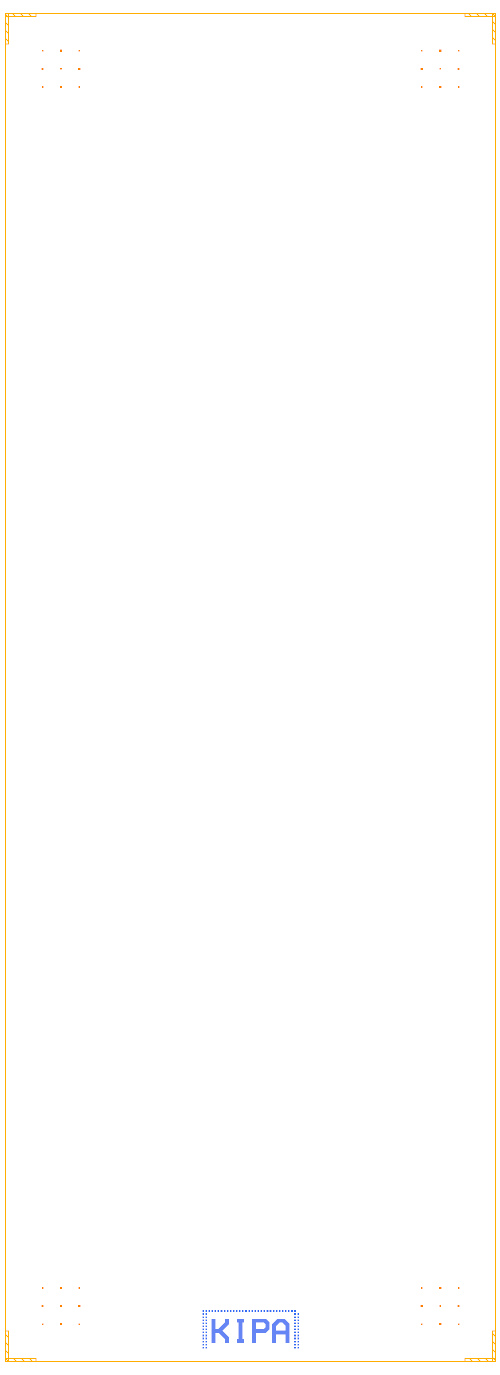

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/amplifiers/unsw_kipa_s1_die.png')

In [5]:
W, H = 4000, 11000
d = Designer("unsw_kipa", box=(0, 0, W, H), chip={"name_chip": "KIPA"}, live=LIVE)
layout_step(d, OUT / "unsw_kipa_s1_die.png", size=(500, 1375), width=220)

## Design 2 · Bond pads (the 100 µm rule)
One `BondPad` on the south edge whose taper ends in the 100/45 µm feed (the source bonds straight onto the feed).
`edge="auto"` puts its outer etch 100 µm from the south edge; `X_FEED` keeps it clear of the south-west marker area.
The pad is the KIPA's only port: it is read in reflection, and the DC bias and the pump come in through it too.

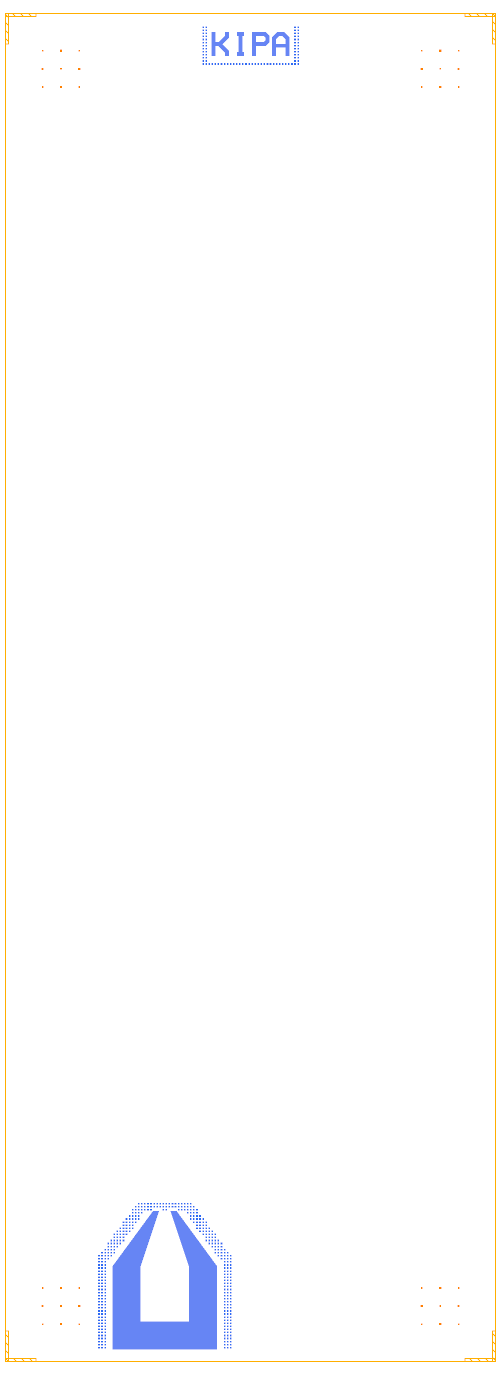

**On the chip so far:** 1 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 1 component(s) `P_IN`.

WindowsPath('examples/designs/amplifiers/unsw_kipa_s2_pad.png')

In [6]:
X_FEED = 1300                                    # clear of the south-west marker area (500 µm)
d.add("P_IN", "BondPad", at=(X_FEED, 300), rot=0, edge="auto", a=100, b=45, pad_width=400)
layout_step(d, OUT / "unsw_kipa_s2_pad.png", size=(500, 1375), width=220)

## Design 3 · The feed: the section plan, the first taper and the 100/45 µm line

The source bonds onto a wide 100/45 µm feed that runs up from the south pad to the first section. First the **section
plan**: the rows are 600 µm apart and the taper positions `xs` are solved so that each route between two tapers (along
a row, a 300 µm U-turn, back along the next row) has its section's length. Then `T0`, the `CpweTaper` from the feed's
100/45 µm to the first low-Z section's 138/6 µm, and `FEED` from the pad to it (its one waypoint turns it from the
pad's column onto the first row). The v1 placed all the tapers in one loop; here that loop is split, `T0` now and
`T1`–`T7` in Design 4 (the same call), so the component order stays T0 … T8.

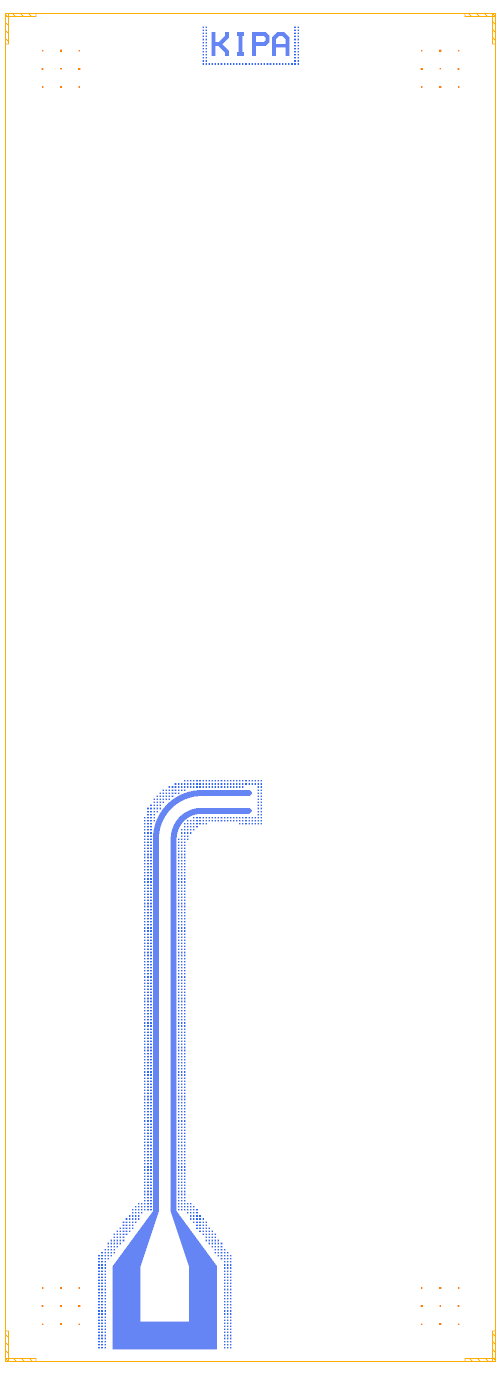

**On the chip so far:** 1 pads · 0 qubits · 1 other components · 1 routes · 0 declared couplings. **This step added** 1 component(s) `T0` and 1 route(s) `FEED`.

WindowsPath('examples/designs/amplifiers/unsw_kipa_s3_feed.png')

In [7]:
X_L, X_R, R_TURN, PITCH = 470.0, 3530.0, 300.0, 600.0
Y0 = 9766.0 - 1000.0 - 7 * PITCH               # the wire sits at the source's height (y = 9.77 mm)
U = PITCH + np.pi * R_TURN - 4 * R_TURN          # a U-turn adds this to the two straights (two r = 300 µm bends)
xs = [2000.0]
for k, (_, _, _, length) in enumerate(SECTIONS):
    x = xs[-1]
    if k % 2 == 0:   # turn at the right end; the next row runs −x
        xs.append(2 * X_R - x - 20 + U - length)
    else:            # turn at the left end; the next row runs +x
        xs.append(length - U + 2 * X_L + 20 - x)
widths = [(100, 45)] + [(a, b) for _, a, b, _ in SECTIONS] + [RES[:2], WIRE[:2]]
with d.batch():
    for k, x in enumerate(xs[:1]):              # T0: the feed → the first low-Z section
        (a0, b0), (a1, b1) = widths[k], widths[k + 1]
        d.add(f"T{k}", "CpweTaper", at=(x - 10 if k % 2 == 0 else x + 10, Y0 + k * PITCH), rot=0 if k % 2 == 0 else 180,
              a=a0, b=b0, a_end=a1, b_end=b1, length=20)
    d.route("FEED", "P_IN.a", "T0.a", a=100, b=45, r=R_TURN, nodes=[(X_FEED, Y0)])
layout_step(d, OUT / "unsw_kipa_s3_feed.png", size=(500, 1375), width=220)

## Design 4 · The nonlinear element: the section boundaries of the SIF and the resonator

On a high-kinetic-inductance film the λ/4 resonator itself is the nonlinear element (its inductance depends on the
current), bounded by the stepped-impedance filter (SIF), its Bragg mirror; both are lines, drawn in Design 5. Here go
the boundaries where the line changes width. The section boundaries are `CpweTaper`s (20 µm, from one section's a/b to
the next): T0 feed → low-Z, T1…T6 between the SIF sections, T7 SIF → resonator, T8 resonator → wire. (Their positions
come from the section plan, Design 3.) The table lists every taper (`T0` from Design 3 too). On the PDK's Nb film the
kinetic share is small (from the v1 run, LOM 1: α_k 0.3 % in the wide sections to 9 % in the wire), so the drawn
resonator is mostly geometric: the topology is the source's, the nonlinearity is not.

| taper | x (µm) | y (µm) | from → to (a/b µm) |
|---|---|---|---|
| T0 | 2000 | 4566 | (100, 45) → (138, 6) |
| T1 | 1982 | 5166 | (138, 6) → (10, 70) |
| T2 | 2090 | 5766 | (10, 70) → (138, 6) |
| T3 | 1892 | 6366 | (138, 6) → (10, 70) |
| T4 | 2180 | 6966 | (10, 70) → (138, 6) |
| T5 | 1802 | 7566 | (138, 6) → (10, 70) |
| T6 | 2270 | 8166 | (10, 70) → (138, 6) |
| T7 | 1718 | 8766 | (138, 6) → (5, 15) |
| T8 | 1470 | 9766 | (5, 15) → (1, 10) |

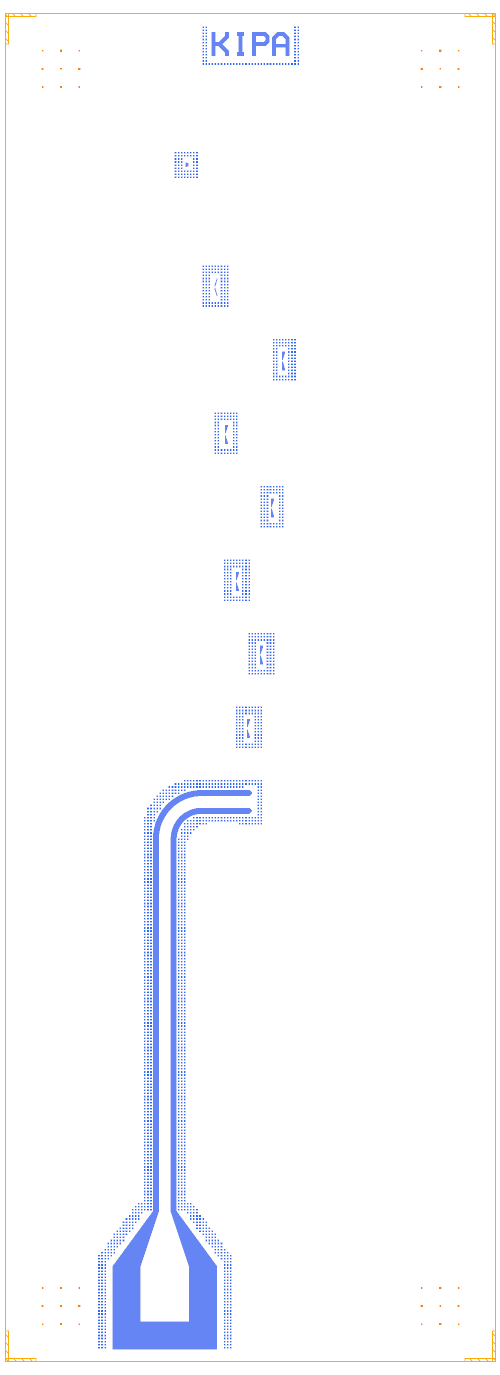

**On the chip so far:** 1 pads · 0 qubits · 9 other components · 1 routes · 0 declared couplings. **This step added** 8 component(s) `T1`, `T2`, `T3`, `T4`, `T5`, `T6`, `T7`, `T8`.

WindowsPath('examples/designs/amplifiers/unsw_kipa_s4_tapers.png')

In [8]:
with d.batch():
    for k, x in enumerate(xs[1:], start=1):     # T1 … T7 on rows 1 … 7: the SIF boundaries
        (a0, b0), (a1, b1) = widths[k], widths[k + 1]
        d.add(f"T{k}", "CpweTaper", at=(x - 10 if k % 2 == 0 else x + 10, Y0 + k * PITCH), rot=0 if k % 2 == 0 else 180,
              a=a0, b=b0, a_end=a1, b_end=b1, length=20)
    y_w = Y0 + 7 * PITCH + 1000
    x8 = X_L + RES[2] - (xs[7] - 10 - X_L) - 1000 - (np.pi * R_TURN - 4 * R_TURN)
    d.add("T8", "CpweTaper", at=(x8, y_w), rot=0, a=RES[0], b=RES[1], a_end=WIRE[0], b_end=WIRE[1], length=20)
show_md(table_md(["taper", "x (µm)", "y (µm)", "from → to (a/b µm)"],
                 [[f"T{k}", x, Y0 + k * PITCH, f"{widths[k]} → {widths[k + 1]}"] for k, x in enumerate(xs)]
                 + [["T8", x8, y_w, f"{RES[:2]} → {WIRE[:2]}"]]))
layout_step(d, OUT / "unsw_kipa_s4_tapers.png", size=(500, 1375), width=220)

## Design 5 · Routing: the SIF sections, the resonator and the spin wire

`S0` … `S6` the SIF sections (each with its own a/b and the U-turn waypoints); `RES` (5/15 µm) from T7 to T8; `WIRE`
(1/10 µm, 1750 µm) to a free end with `term=0` — the short to ground at the end of the spin wire. The first picture is
the chip so far, the second zooms on the end of the resonator and the 1 µm wire with its short.

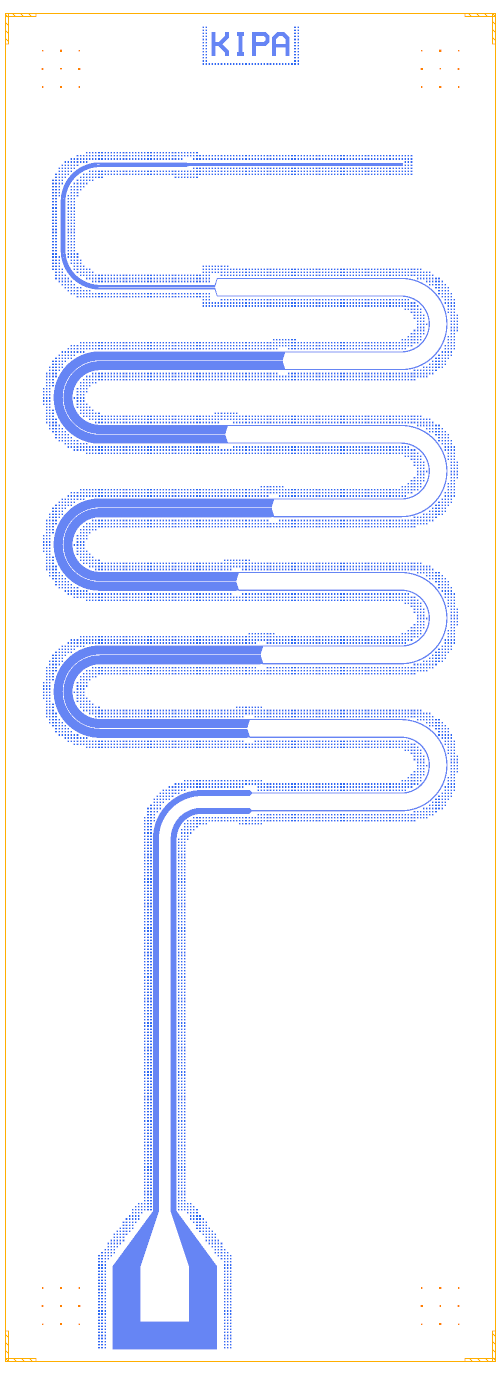

**On the chip so far:** 1 pads · 0 qubits · 9 other components · 10 routes · 0 declared couplings. **This step added** 9 route(s) `S0`, `S1`, `S2`, `S3`, `S4`, `S5`, `S6`, `RES` … (+1).

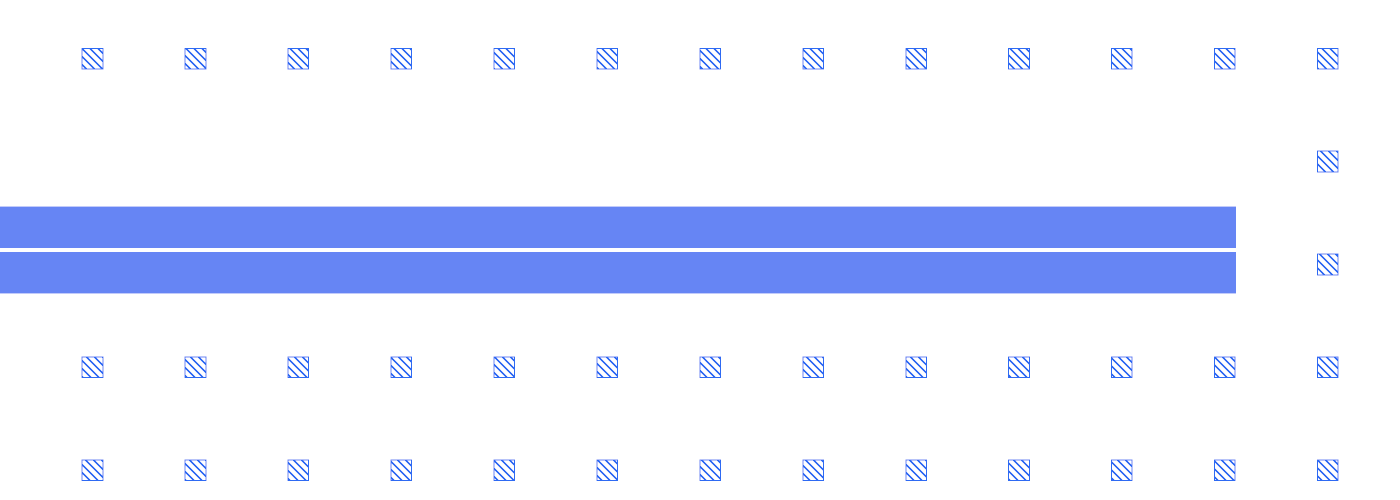

WindowsPath('examples/designs/amplifiers/unsw_kipa_s5_wire.png')

In [9]:
with d.batch():
    for k, (name, a, b, _) in enumerate(SECTIONS):
        xe = X_R if k % 2 == 0 else X_L
        d.route(name, f"T{k}.b", f"T{k + 1}.a", a=a, b=b, r=R_TURN,
                nodes=[(xe, Y0 + k * PITCH), (xe, Y0 + (k + 1) * PITCH)])
    d.route("RES", "T7.b", "T8.a", a=RES[0], b=RES[1], r=R_TURN, nodes=[(X_L, Y0 + 7 * PITCH), (X_L, y_w)])
    x_end = x8 + 20 + WIRE[2]
    d.route("WIRE", "T8.b", Designer.free_end((x_end, y_w), term=0), a=WIRE[0], b=WIRE[1])
layout_step(d, OUT / "unsw_kipa_s5_routes.png", size=(500, 1375), width=220)
snap(d, OUT / "unsw_kipa_s5_wire.png", box=(x_end - 300, y_w - 60, x_end + 40, y_w + 60), size=(1400, 500), width=560)

## Design 6 · The whole chip: the sim group, the save

**Sim group.** `resonator`: `T7`, `RES`, `T8` and `WIRE` with an 80 µm margin, for a Q3D C-matrix; the last SIF
section `S6` is cut at the box edge. The design sets no targets (Results 4 puts one on a copy).

**No centring.** The content sits where the source puts it (the feed from the south edge, the wire 9.77 mm up), so it
is off-centre in y by design (Check 1's `pdk_report` measures it).

**Save.** `save_design` writes `unsw_kipa.json` and compares it with the file it replaces (the previous run's, e.g.
the `.v1` notebook's): it should say *same design*. The table compares the drawn lengths with the source's (from the
v1 run every section at its source length; the feed longer, from the pad at the PDK edge up to the first row). The
picture is the whole chip.

**Same design as before:** `examples/designs/amplifiers/unsw_kipa.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

| route | a / b (µm) | drawn (µm) | source (µm) |
|---|---|---|---|
| S0 | 138/6 | 3400 | 3400 |
| S1 | 10/70 | 3455 | 3455 |
| S2 | 138/6 | 3400 | 3400 |
| S3 | 10/70 | 3455 | 3455 |
| S4 | 138/6 | 3400 | 3400 |
| S5 | 10/70 | 3455 | 3455 |
| S6 | 138/6 | 3394 | 3394 |
| RES | 5/15 | 2981 | 2981 |
| WIRE | 1/10 | 1750 | 1750 |
| FEED | 100/45 | 3902 | 1700 |

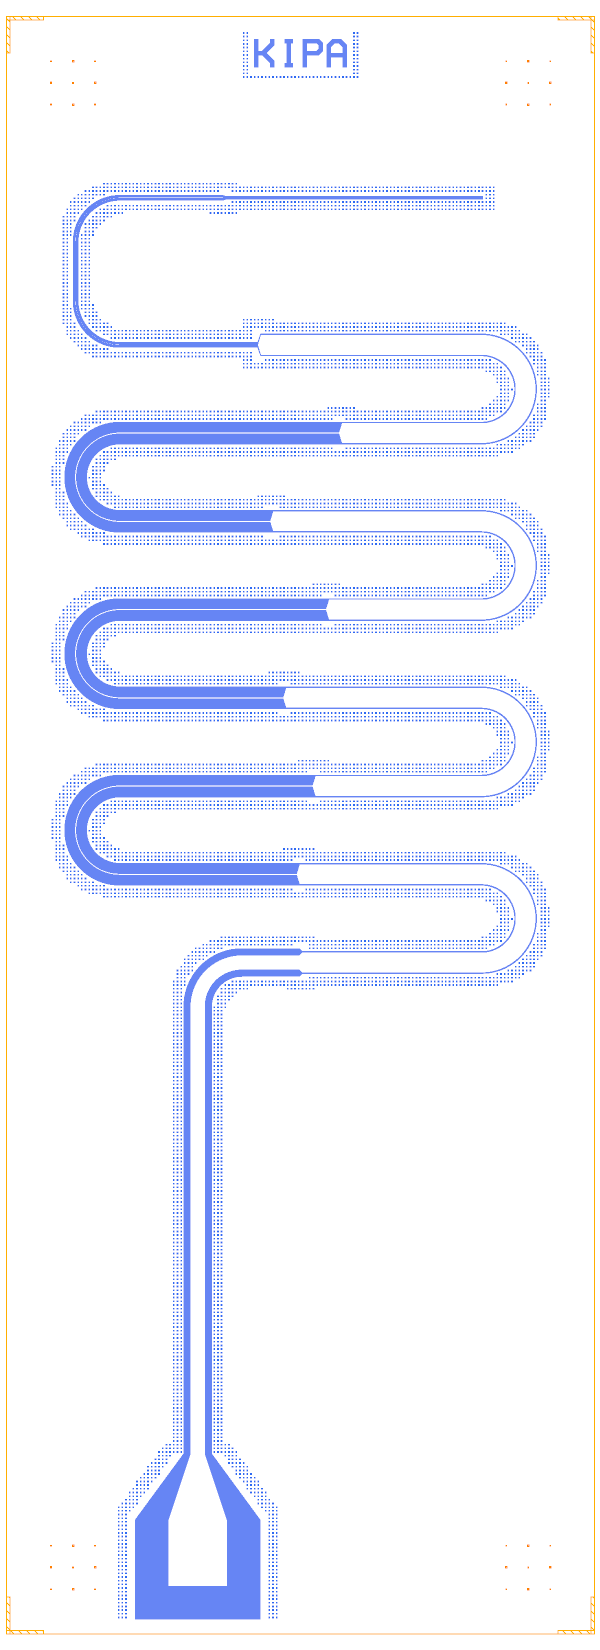

**On the chip so far:** 1 pads · 0 qubits · 9 other components · 10 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/amplifiers/unsw_kipa_s6_chip.png')

In [10]:
d.sim_group("resonator", ["T7", "RES", "T8", "WIRE"], margin_um=80, analyses=["q3d_cmatrix"])
if not LIVE:
    d.show()
DESIGN, same = save_design(d, OUT / "unsw_kipa.json")
display(Markdown(same))
lengths = d.result.route_lengths()
show_md(table_md(["route", "a / b (µm)", "drawn (µm)", "source (µm)"],
                 [[n, f"{a}/{b}", lengths[n], L] for n, a, b, L in SECTIONS]
                 + [["RES", "5/15", lengths["RES"], RES[2]], ["WIRE", "1/10", lengths["WIRE"], WIRE[2]],
                    ["FEED", "100/45", lengths["FEED"], 1700]]))
layout_step(d, OUT / "unsw_kipa_s6_chip.png", size=(600, 1650), width=260)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC
No junctions; the content sits where the source puts it (feed from the south edge, the wire 9.77 mm up), so it is
off-centre in y by design.

Expected here (from the v1 run): **DRC clean**, no PDK design warnings (no junctions); content centre − die centre
(+0, −558) µm.

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip box
and the frame: **errors** would block fab, **warnings** are layout hints, **PDK design warnings** (`pad_edge`,
`pdk_rn`, …) flag a PDK margin and are never fixed by retuning. `pdk_report(d)` sums up the PDK side.

In [ ]:
print(d.drc())
show_md(pdk_report(d))

## Check 2 · Netlist
The builder sees one chain of lines from the pad to the shorted wire end (the tapers are pass-through sections):
with a 50 Ω pad on one end it is a wire on the pad's node — the LOM's one-Z0 line model does not describe a
stepped-impedance filter. The SIF resonator is therefore simulated as a transmission-line cascade (LOM 1),
section by section, from the drawn lengths and widths.

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The circuit model: the section cascade

Each section is a TL (Z0, v_p from `cpw_properties` on the PDK stack, Nb kinetic inductance included); the input
reflection at the feed: the resonance sits inside the SIF stop band. One SIF period's Bloch attenuation shows the
stop band. The plot is in LOM 2.

In [ ]:
f = np.linspace(1e9, 16e9, 30001)
def tl(freq, a, b, length_um):
    q = cpw_properties(7.0, a, b, PDK.name)
    bl = 2 * np.pi * freq / q["vp_m_s"] * length_um * 1e-6
    z = q["Z0_ohm"]
    m = np.zeros(freq.shape + (2, 2), dtype=complex)
    m[..., 0, 0] = m[..., 1, 1] = np.cos(bl)
    m[..., 0, 1] = 1j * z * np.sin(bl)
    m[..., 1, 0] = 1j * np.sin(bl) / z
    return m, q
chain, rows = [], []
for name, a, b, _ in SECTIONS:
    m, q = tl(f, a, b, lengths[name])
    chain.append(m)
    rows.append([name, f"{a}/{b}", q["Z0_ohm"], q["alpha_k"], lengths[name]])
m_res, q_res = tl(f, *RES[:2], lengths["RES"])
m_w, q_w = tl(f, *WIRE[:2], lengths["WIRE"])
rows += [["RES", "5/15", q_res["Z0_ohm"], q_res["alpha_k"], lengths["RES"]],
         ["WIRE", "1/10", q_w["Z0_ohm"], q_w["alpha_k"], lengths["WIRE"]]]
show_md(table_md(["section", "a/b (µm)", "Z0 (Ω)", "α_k", "length (µm)"], rows))
total = amp.cascade(*chain, m_res, m_w)
zin = total[..., 0, 1] / total[..., 1, 1]          # far end shorted: Z_in = B / D
s11 = (zin - 50) / (zin + 50)
period = amp.cascade(chain[0], chain[1])
att = amp.bloch(period).real
inside = att > 0.5
fr, kr = amp.resonance(f[inside], s11[inside]) if inside.any() else (float("nan"), float("nan"))
show_md(f"SIF stop band (attenuation > 0.5 Np/period): {f[inside][0] / 1e9:.2f}–{f[inside][-1] / 1e9:.2f} GHz; "
        f"resonance in it at {fr / 1e9:.3f} GHz, κ/2π ≈ {kr / 1e6:.3g} MHz (Q_ext ≈ {fr / kr:.3g}) on Nb.")

## LOM 2 · The model in a plot

The reflection phase at the feed (in turns) and one SIF period's Bloch attenuation: the resonance is the phase step
inside the stop band (where the attenuation is high).

In [ ]:
plot(OUT / "unsw_kipa_response.png", [(f / 1e9, np.degrees(np.unwrap(np.angle(s11))) / 360, "S11 phase (turns)"),
                                       (f / 1e9, att, "SIF attenuation per period (Np)", "--")],
     "frequency (GHz)", "", "KIPA rebuild on PDK Nb: reflection phase and the SIF stop band");

## LOM 3 · One change by hand: the resonator length
Before the FEM, a design step by hand. One property: the 5/15 µm resonator 2981 → 2500 µm (the resonance moves up
inside the stop band). On the cascade only: the drawn chip is not touched. From the v1 run: f_r 11.72 → 12.52 GHz, κ
2.8 → 15 MHz (near the stop band's upper edge the mirror leaks).

In [ ]:
m_res2, _ = tl(f, *RES[:2], lengths["RES"] - 481)
tot2 = amp.cascade(*chain, m_res2, m_w)
s2 = (tot2[..., 0, 1] / tot2[..., 1, 1] - 50) / (tot2[..., 0, 1] / tot2[..., 1, 1] + 50)
fr2, kr2 = amp.resonance(f[inside], s2[inside])
show_md(table_md(["resonator (µm)", "f_r (GHz)", "κ/2π (MHz)"],
                 [[lengths["RES"], fr / 1e9, kr / 1e6], [lengths["RES"] - 481, fr2 / 1e9, kr2 / 1e6]]))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS and the component simulation

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With `RUN_FEM =
False` (the default) the jobs are only exported: the cells load results that were solved and kept before (in
`examples/designs/amplifiers/fem/<job>/`), and otherwise say what would appear. Simulate 3–4 say why there is no
eigenmode or full-wave run here.

## Simulate 1 · Export to HFSS
A Q3D C-matrix job of the resonator + wire (the wire's capacitance and the taper parasitics); a driven S11 run of
the whole line is the right extraction for the SIF (not exported here: Simulate 3–4).

The wire ends in a short to ground (`term=0`). From the v1 run's job table the C-matrix has two nets, `T7.b` and
`T8.b` (named after the ports they start at), and the export warned (twice) that it could not make a polygon for port
2, `T8.a`, where the 5/15 µm resonator meets the taper to the 1 µm wire: read the export notes for both.

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/amplifiers/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["resonator"])
display(Markdown(jobs_md(jobs)))

## Simulate 2 · Component simulation: the resonator's Q3D C-matrix

`fem_stage` solves the job with `RUN_FEM`, else loads its kept results, else says that there are none. Results 2 puts
the nets' capacitance next to the CPW formula's.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode, and Simulate 4 · the full-wave run: not for this chip

The design has no eigenmode group, and a box round the resonator cuts the SIF: its mode's Q would be set by the cut
line's 50 Ω port, not by the mirror. The right extraction is a driven S11 of the whole line, pad to wire (the v1 says
so), which needs a sim group round the whole 4 × 11 mm chip: a new sim group changes the design file, so it is not
added here. No eigenmode or driven job is exported.

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the FEM results

No eigenmodes to plot (Simulate 3), and the Q3D gives a few capacitances: Results 2 reads them.

## Results 2 · The values

The C-matrix nets' capacitance to ground (the Maxwell row sums) next to the CPW formula's capacitance of the resonator
line and the wire (C' = 1 / (Z0 v_p) from `cpw_properties`, LOM 1, times the drawn length). Which conductor each net
is shows in the export notes (Simulate 1): the table does not pair them.

In [ ]:
C_NET = cmatrix_to_ground(keep_q3d["resonator"])  # {net: C to ground (fF)}; {} without results


def c_line(q, length_um):
    """The CPW formula's capacitance of a line (fF): C' = 1 / (Z0 v_p) of its cpw_properties, times its length."""
    return length_um * 1e-6 / (q["Z0_ohm"] * q["vp_m_s"]) * 1e15


C_EST = {"RES (5/15 µm)": c_line(q_res, lengths["RES"]), "WIRE (1/10 µm)": c_line(q_w, lengths["WIRE"])}
show_md(table_md(["line (CPW formula)", "C (fF)"], [[key, c] for key, c in C_EST.items()]))
if C_NET:
    show_md(table_md(["C-matrix net (Q3D)", "C to ground (fF)"], [[key, c] for key, c in C_NET.items()]))
else:
    print("No Q3D results yet (RUN_FEM = True): a second table would list the C-matrix nets' capacitance to ground.")

## Results 3 · FEM against the LOM

The sum over the C-matrix nets against the CPW formula's resonator line plus wire, with the difference in %: a check
of the formula the cascade uses, valid when the nets are those two conductors (the export notes say). The KIPA's
feedback (Results 4) stays on the cascade: a Q3D does not give f_r, and the SIF that sets κ is outside this box.

In [ ]:
if C_NET:
    display(Markdown(fem_vs_lom_md([("C, resonator line + wire (fF)", sum(C_EST.values()), sum(C_NET.values()),
                                     "Q3D, all nets of the box (see the export notes)")])))
else:
    print("No FEM results yet: with RUN_FEM = True this row puts the CPW formula's C of the resonator line and the "
          "wire next to the Q3D's, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The KIPA's resonance must sit inside the SIF's stop band, the mirror that keeps it in while letting the DC bias
through; LOM 3 shows κ growing fast near the band's upper edge (from the v1 run: band 5.84–12.61 GHz, f_r 11.72 GHz).
The source's film is not in its GDS, so on Nb the exercise target is **f_r = 11.20 GHz ± 5 MHz**, ≈ 0.5 GHz deeper
into the band, on a copy (`target_copy` → `build/unsw_kipa_target.json`).

`loop.feedback` tunes qubit–readout pairs; a KIPA has none, so the feedback is the cascade's rule on one knob, the
resonator `RES`'s length. `RES` is drawn by its waypoints (its length is its geometry, not a `meander=`), so the knob
moves the taper `T8` and the wire's shorted end along x together: RES's last straight gets longer by the same amount,
the wire keeps its 1750 µm. The rule is f ∝ ℓ^p with p from LOM 3's two points (≈ −0.37 by the v1 run's numbers); by
the rule RES gets ≈ 390 µm longer, within the die (`T8` stays past RES's last bend, the wire's end 150 µm inside the
die edge: the bounds below).

In [ ]:
F_T, F_TOL = 11.20, 0.005                        # the exercise target and its tolerance (GHz)
DESIGN_T = target_copy(DESIGN, {"RES": {"f_GHz": F_T}})


def f_res(len_res, len_wire):
    """The cascade's resonance (GHz) and κ (MHz): the drawn SIF (LOM 1) with a resonator and a wire of these lengths."""
    tot = amp.cascade(*chain, tl(f, *RES[:2], len_res)[0], tl(f, *WIRE[:2], len_wire)[0])
    z = tot[..., 0, 1] / tot[..., 1, 1]          # far end shorted: Z_in = B / D
    f0, k0 = amp.resonance(f[inside], ((z - 50) / (z + 50))[inside])
    return f0 / 1e9, k0 / 1e6


L0 = float(lengths["RES"])
P0 = float(np.log(fr2 / fr) / np.log((L0 - 481) / L0))   # d ln f / d ln ℓ from LOM 3's two points
LO = L0 - (x8 - X_L - R_TURN - 50)               # T8 at least 50 µm past the end of RES's last bend
HI = L0 + (W - 150 - x_end)                      # the wire's shorted end 150 µm inside the die edge
F_NOW = fr / 1e9
L1 = rule_step(L0, F_NOW, F_T, P0)
show_md(f"**RES:** now {F_NOW:.4f} GHz (κ/2π {kr / 1e6:.2f} MHz), target {F_T} ± {F_TOL} GHz → length {L0:.0f} → "
        f"**{L1:.0f} µm** (f ∝ ℓ^{P0:.3f}; the knob's range {LO:.0f}–{HI:.0f} µm)")

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k moves `T8` and the wire's end, is built (the 4 × 11 mm chip, seconds)
and its drawn `RES` and `WIRE` lengths go into the cascade with the drawn SIF; the next step uses the exponent of the
last two points (a secant), until f_r is within 5 MHz of 11.20 GHz or `MAX_ITER` steps are made. Each revision is a
design file (`build/unsw_kipa_rev<k>.json`). No FEM per revision: the design's one FEM job is a Q3D, which does not
give f_r (Results 3). The table shows each step's f_r against the target and the knob it moved; the plot the residual
in tolerances (on target below 1).

In [ ]:
def f_of(k, it):
    """Revision it: RES k µm long (T8 and the wire's shorted end moved along x by k − ℓ0); built, its drawn lengths
    into the cascade."""
    dx = k - L0
    d2 = design_copy(DESIGN_T, f"_rev{it}")
    d2["T8"].set(at=(x8 + dx, y_w))
    d2["WIRE"].set(to=Designer.free_end((x_end + dx, y_w), term=0))
    path = d2.save(Path("build") / f"unsw_kipa_rev{it}.json")
    drawn = rebuild(d2).route_lengths()
    return f_res(drawn["RES"], drawn["WIRE"])[0], path


history = rule_iterate(f_of, "RES.f_GHz", "RES.length", L0, F_T, F_TOL, P0, max_iter=MAX_ITER,
                       start=(F_NOW, DESIGN_T), fem=False, bounds=(LO, HI))
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "unsw_kipa_feedback.png")
print("last design:", history[-1]["design"], "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export
The design JSON saved in Design 6 is the deliverable: `qcc build examples/designs/amplifiers/unsw_kipa.json`, `qcc
mask …` and the KLayout plugin read it.

In [ ]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
if d.result is None:
    d.show()
fab = {}
export_fab(d.result, Path("build") / f"{d.design.name}_fab.oas", report=fab)
show_md(f"cheese: {fab.get('cheese_source')}; written: " + ", ".join(f"{k} {n}" for k, n in fab["written"].items()))

## Fab 2 · Snapshots — the rebuild next to the original
The full rebuilt die; the end of the resonator and the 1 µm wire with its short; the original BA13 GDS (rendered
read-only from `build/external/kipa_zenodo_7600250/`).

In [ ]:
show_snapshot(d, OUT / "unsw_kipa.png", size=(800, 2200), width=300)
show_snapshot(d, OUT / "unsw_kipa_wire.png", box=(x_end - 300, y_w - 60, x_end + 40, y_w + 60), size=(1400, 500),
              width=560)
ref = ROOT / "build/external/kipa_zenodo_7600250/BA13_device_gds.GDS"
if ref.exists():
    from quantcore_circuits.live.snapshot import snapshot
    display(Image(filename=str(snapshot(str(ref), OUT / "unsw_kipa_original.png", size=(800, 2200))), width=300))

## Summary
* **Matches the source:** the section sequence (100/45 feed, 4 × 138/6 and 3 × 10/70 SIF sections, 5/15 resonator,
  1 µm wire shorted to ground) with the measured widths and lengths, the 4 × 11 mm die, the feed from the south.
* **Differs:** our serpentine (300 µm U-turns, tapers at the section boundaries), a Quantcore `BondPad` on the
  feed, the PDK Nb film instead of the source's kinetic film — on Nb the resonator is mostly geometric, so f_r and
  the nonlinearity differ from the device (its film is not in the GDS).
* **PDK design warnings:** none (no junctions).
* **Not modelled:** the 3WM gain (needs the film's I* and L_s: see `ki_twpa_serpentine` for the CME model), the
  donor spins.
* **Layout:** built in six segments (die, pad, the feed with the first taper, the section boundaries, the SIF sections
  with the resonator and the wire, the whole chip); the saved JSON is the v1 notebook's.
* **Feedback:** an exercise target on a copy (f_r 11.20 GHz, deeper inside the SIF stop band): the cascade's rule on
  the resonator length (T8 and the wire's end moved), iterated with a secant; each revision built, LOM only.
* **FEM:** the resonator's Q3D job is exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the
  Simulate and Results cells. No eigenmode or driven job (Simulate 3–4).